# Preliminary EDA: Where Should I Drive Next? (Bangkok, 2025)

This notebook explores one year of Bangkok taxi GPS data before any modelling. Run the cells from top to bottom.

**Datasets used**

| Dataset | What it contains | Source |
|---|---|---|
| iTIC probe data, January to December 2025 (main) | One row per GPS report: vehicle ID, GPS valid flag, latitude, longitude, time (GMT+7), speed, heading, For Hire light (1 = empty), engine on/off. Taxis report every 1 minute with the engine on and every 3 minutes with it off | 12 monthly files `PROBE-2025MM.tar.bz2` from https://traffic.longdo.com/opendata/probe-data/ (iTIC, CC BY 4.0). Do not extract them |
| Open-Meteo hourly weather | Rain and temperature for Bangkok, 2025 | Downloaded automatically in Step 11 (needs internet) |
| Thai public holidays | Official 2025 holidays | `holidays` package, or the built-in list below |

**How it works.** The raw data is about 80 GB once decompressed, so it is never loaded at once:
- **Step 1** reads each monthly file and saves only Bangkok taxi records, one small file per day.
- **Step 2** turns each day into trips, empty periods and hexagon-hour counts, and saves them.

Both steps skip days that are already done, so you can stop and restart. The first full run takes a few hours; later runs take minutes.

In [1]:
# Run once if these packages are missing (h3 is optional; a built-in hexagon grid is used without it)
# !pip install pandas numpy matplotlib h3 holidays requests pyarrow

## Step 0. Settings

The cleaning limits are **starting values**; the plots below tell us whether to keep or change them.

In [2]:
import glob, io, os, tarfile, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

DATA_DIR = os.path.expanduser("~/Downloads")      # folder with the PROBE-2025MM.tar.bz2 files
OUT = "eda_output_bangkok"
DAYS_DIR = os.path.join(OUT, "taxi_days")          # Step 1 output
EVENTS_DIR = os.path.join(OUT, "day_tables")       # Step 2 output

# Greater Bangkok, including Nonthaburi, Pathum Thani, Samut Prakan and both airports
BBOX = dict(lat_min=13.45, lat_max=14.15, lon_min=100.25, lon_max=100.95)
MIN_SWITCHES = 4        # a vehicle counts as a taxi on a day if its For Hire light changes at least this often
MAX_SPEED_KMH = 150     # faster jumps between two points are GPS errors
GAP_SEC = 600           # a gap longer than 10 minutes ends an empty period (censored)
MAX_VACANT_MIN = 180    # empty periods longer than 3 hours are breaks, not searching
HEX_AREA_KM2 = 0.74     # hexagon size (same as H3 resolution 8)
DOWNLOAD_WEATHER = True

COLS = ["vid", "gps", "lat", "lon", "ts", "speed", "heading", "light", "acc"]
for d in (OUT, DAYS_DIR, EVENTS_DIR):
    os.makedirs(d, exist_ok=True)
plt.rcParams["figure.dpi"] = 100
ARCHIVES = sorted(glob.glob(os.path.join(DATA_DIR, "PROBE-2025*.tar.bz2")))
print(len(ARCHIVES), "monthly files found")

12 monthly files found


Helper functions: hexagons, distance and saving figures.

Hexagons use the `h3` package (resolution 8) when it is installed. Otherwise a built-in hexagonal grid with the same cell size (0.74 km²) is used, so the notebook runs anywhere.

In [3]:
try:
    import h3
    GRID = "h3"
except ImportError:
    GRID = "hexgrid"
print("Hexagon grid:", GRID)

LAT0, LON0 = 13.75, 100.50
KM_LAT, KM_LON = 110.574, 111.320 * np.cos(np.radians(LAT0))
SIDE = np.sqrt(2 * HEX_AREA_KM2 / (3 * np.sqrt(3)))       # hexagon side in km

def to_hex(lat, lon):
    lat, lon = np.asarray(lat, float), np.asarray(lon, float)
    if GRID == "h3":
        f = h3.latlng_to_cell if hasattr(h3, "latlng_to_cell") else h3.geo_to_h3
        return np.array([f(a, b, 8) for a, b in zip(lat, lon)])
    x, y = (lon - LON0) * KM_LON, (lat - LAT0) * KM_LAT
    q, r = (np.sqrt(3) / 3 * x - y / 3) / SIDE, (2 / 3 * y) / SIDE
    s = -q - r
    rq, rr, rs = np.round(q), np.round(r), np.round(s)
    dq, dr, ds = np.abs(rq - q), np.abs(rr - r), np.abs(rs - s)
    fix_q = (dq > dr) & (dq > ds)
    fix_r = ~fix_q & (dr > ds)
    rq = np.where(fix_q, -rr - rs, rq)
    rr = np.where(fix_r, -rq - rs, rr)
    return ((rq.astype(np.int64) + 5000) * 10000 + (rr.astype(np.int64) + 5000))

def hex_center(cells):
    if GRID == "h3":
        f = h3.cell_to_latlng if hasattr(h3, "cell_to_latlng") else h3.h3_to_geo
        return np.array([f(c) for c in cells])
    cells = np.asarray(cells, np.int64)
    q, r = cells // 10000 - 5000, cells % 10000 - 5000
    x, y = SIDE * (np.sqrt(3) * q + np.sqrt(3) / 2 * r), SIDE * 1.5 * r
    return np.column_stack([LAT0 + y / KM_LAT, LON0 + x / KM_LON])

def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371.0 * 2 * np.arcsin(np.sqrt(a))

def show(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(OUT, name), dpi=150)
    plt.show()

Hexagon grid: hexgrid


## Step 1. Extract Bangkok taxi records from each monthly file

For each day we keep rows that have a valid GPS fix, a timestamp on that day and a position inside greater Bangkok. We then keep only vehicles whose For Hire light changes at least `MIN_SWITCHES` times that day. Other vehicles never switch the light, so they are not taxis.

In [4]:
def filter_day(raw_bytes, day):
    # keep valid, same-day, in-Bangkok records of vehicles that behave like taxis
    d = pd.read_csv(io.BytesIO(raw_bytes), header=None, names=COLS,
                    dtype={"vid": "category", "gps": "int8", "speed": "int16", "heading": "int16", "light": "int8", "acc": "int8"})
    n_all, n_veh = len(d), d["vid"].nunique()
    d["ts"] = pd.to_datetime(d["ts"], errors="coerce")
    d = d[(d["gps"] == 1) & (d["ts"].dt.normalize() == pd.Timestamp(day))]
    n_valid = len(d)
    d = d[d["lat"].between(BBOX["lat_min"], BBOX["lat_max"]) & d["lon"].between(BBOX["lon_min"], BBOX["lon_max"])]
    n_bkk = len(d)
    d = d.sort_values(["vid", "ts"]).drop_duplicates(["vid", "ts"])
    sw = d["light"].ne(d.groupby("vid", observed=True)["light"].shift()) & d["vid"].eq(d["vid"].shift())
    n_sw = sw.groupby(d["vid"], observed=True).sum()
    taxis = n_sw[n_sw >= MIN_SWITCHES].index
    d = d[d["vid"].isin(taxis)]
    out = pd.DataFrame({"vid": d["vid"].astype(str).values,
                        "t": (d["ts"].astype("int64") // 10**9).astype("int64").values,
                        "lat": d["lat"].astype("float32").values, "lon": d["lon"].astype("float32").values,
                        "speed": d["speed"].values, "occ": (1 - d["light"]).astype("int8").values, "acc": d["acc"].values})
    out.attrs["log"] = dict(day=day, rows=n_all, vehicles=n_veh, removed_invalid_or_wrong_day=n_all - n_valid,
                            removed_outside_bangkok=n_valid - n_bkk, taxis=len(taxis), taxi_rows=len(out))
    return out

def save_day(out, day):
    dst = os.path.join(DAYS_DIR, day + ".pkl")
    out.to_pickle(dst + ".tmp", compression=None)
    os.replace(dst + ".tmp", dst)

def extract_month(archive):
    month = os.path.basename(archive)[6:12]
    n_days = pd.Period(f"{month[:4]}-{month[4:]}").days_in_month
    if len(glob.glob(os.path.join(DAYS_DIR, month + "*.pkl"))) >= n_days:
        return
    with tarfile.open(archive, "r|bz2") as tar:                 # stream: no need to extract
        for m in tar:
            if not m.name.endswith(".csv.out"):
                continue
            day = os.path.basename(m.name)[:8]
            if os.path.exists(os.path.join(DAYS_DIR, day + ".pkl")):
                continue
            out = filter_day(tar.extractfile(m).read(), day)
            save_day(out, day)
            print(day, f"rows {out.attrs['log']['rows']:,}", f"taxis {out.attrs['log']['taxis']:,}", flush=True)

t0 = time.time()
for a in ARCHIVES:
    extract_month(a)
print(f"Step 1 done in {time.time() - t0:.0f}s;", len(glob.glob(os.path.join(DAYS_DIR, "*.pkl"))), "days saved")

Step 1 done in 0s; 365 days saved


## Step 2. Build trips, empty periods and hexagon-hour counts for each day

- **Pickup:** light goes from on (empty) to off. **Drop-off:** off to on.
- **Trip:** pickup to the next drop-off. **Empty period (waiting time):** drop-off to the next pickup.
- **Censored:** the empty period ended without a pickup (a gap over `GAP_SEC`, or the end of the data). We only know the wait was *at least* this long.
- **Flicker:** a single report with a different light status between two reports with the same status is treated as noise.
- Each day is processed together with the first 3 hours of the next day, so trips and empty periods that cross midnight are not cut.
- We also record how much of each empty period had the engine off, and summary counts for the quality plots.

In [5]:
GAP_BINS = np.arange(0, 905, 15)
SPD_BINS = np.arange(0, 252, 2)

def bangkok_fare(km, slow_min):
    # Bangkok taxi fare from 13 January 2023: 35 baht first km, rising rate per km, 3 baht per minute at 6 km/h or less
    fare = 35.0 + 3.0 * slow_min
    for lo, hi, rate in [(1, 10, 6.5), (10, 20, 7.0), (20, 40, 8.0), (40, 60, 8.5), (60, 80, 9.0), (80, 1e9, 10.5)]:
        fare += np.clip(np.minimum(km, hi) - lo, 0, None) * rate
    return fare

def process_day(day, days_set):
    dst = os.path.join(EVENTS_DIR, day + ".pkl")
    if os.path.exists(dst):
        return
    d = pd.read_pickle(os.path.join(DAYS_DIR, day + ".pkl"))
    log = d.attrs.get("log", {})
    day_start = int(pd.Timestamp(day).value // 10**9)
    day_end = day_start + 86400
    nxt = (pd.Timestamp(day) + pd.Timedelta(days=1)).strftime("%Y%m%d")
    if nxt in days_set:
        n = pd.read_pickle(os.path.join(DAYS_DIR, nxt + ".pkl"))
        d = pd.concat([d, n[n["t"] < day_end + 3 * 3600]], ignore_index=True)
    d = d.sort_values(["vid", "t"]).reset_index(drop=True)
    same = d["vid"].eq(d["vid"].shift())
    dist = haversine_km(d["lat"].shift(), d["lon"].shift(), d["lat"], d["lon"])
    gap = np.where(same, d["t"].diff(), np.nan)
    jump = np.where(same & (gap > 0), dist / (gap / 3600), np.nan)
    today = (d["t"] < day_end).to_numpy()
    st = {"log": log}
    st["gap_hist_on"] = np.histogram(np.clip(gap[today & (d["acc"] == 1)], 0, 900), GAP_BINS)[0]
    st["gap_hist_off"] = np.histogram(np.clip(gap[today & (d["acc"] == 0)], 0, 900), GAP_BINS)[0]
    st["n_gaps"] = int(np.sum(today & ~np.isnan(gap)))
    st["n_gaps_over"] = int(np.sum(today & (gap > GAP_SEC)))
    st["jump_hist"] = np.histogram(np.clip(jump[today], 0, 250), SPD_BINS)[0]
    st["speed_hist"] = np.histogram(np.clip(d["speed"].to_numpy()[today], 0, 250), SPD_BINS)[0]
    keep = ~(jump > MAX_SPEED_KMH)
    st["removed_speed_jumps"] = int(np.sum(~keep & today))
    d = d[keep].reset_index(drop=True)
    sp, sn = d["vid"].eq(d["vid"].shift()), d["vid"].eq(d["vid"].shift(-1))
    fl = sp & sn & d["occ"].ne(d["occ"].shift()) & d["occ"].shift().eq(d["occ"].shift(-1))
    d.loc[fl, "occ"] = d["occ"].shift()[fl].astype("int8")
    st["flicker_fixed"] = int(fl[d["t"] < day_end].sum())
    td = d[d["t"] < day_end]
    st["records_per_taxi"] = td.groupby("vid").size().to_numpy()
    st["stationary"] = int((td["speed"] == 0).sum())
    st["clean_rows"] = len(td)
    st["taxis"] = td["vid"].nunique()
    hr = ((td["t"] - day_start) // 3600).clip(0, 23).to_numpy()
    st["occ_sum_by_hour"] = np.bincount(hr, weights=td["occ"].to_numpy(), minlength=24)
    st["rows_by_hour"] = np.bincount(hr, minlength=24)
    e = td[td["occ"] == 0]
    e = pd.DataFrame({"hex": to_hex(e["lat"], e["lon"]), "hour": (e["t"] // 3600).to_numpy(), "vid": e["vid"].to_numpy()})
    vacant_taxis = e.groupby(["hex", "hour"])["vid"].nunique().rename("vacant_taxis").astype("int16")

    same = d["vid"].eq(d["vid"].shift())
    prev = d["occ"].shift()
    pick = (same & (prev == 0) & (d["occ"] == 1)).to_numpy()
    drop = (same & (prev == 1) & (d["occ"] == 0)).to_numpy()
    trips, vac = [], []
    starts = np.flatnonzero(~same.to_numpy())
    ends = np.append(starts[1:], len(d))
    T, LA, LO, SP, AC = (d[c].to_numpy() for c in ["t", "lat", "lon", "speed", "acc"])
    for a, b in zip(starts, ends):
        t, la, lo, spd, acc = T[a:b], LA[a:b], LO[a:b], SP[a:b], AC[a:b]
        pk, dp = np.flatnonzero(pick[a:b]), np.flatnonzero(drop[a:b])
        gaps = np.diff(t)
        for i in pk:
            if t[i] >= day_end:
                break
            j = dp[dp > i]
            if len(j) == 0:
                break
            j = j[0]
            if np.any(gaps[i:j] > GAP_SEC):
                continue
            km = float(np.sum(haversine_km(la[i:j], lo[i:j], la[i + 1:j + 1], lo[i + 1:j + 1])))
            slow = float(np.sum(gaps[i:j][spd[i:j] <= 6]) / 60)
            trips.append((t[i], t[j], la[i], lo[i], la[j], lo[j], km, slow))
        for i in dp:
            if t[i] >= day_end:
                break
            nx = pk[pk > i]
            end = nx[0] if len(nx) else len(t) - 1
            big = np.flatnonzero(gaps[i:end] > GAP_SEC)
            if len(big):
                end, cen = i + big[0], True
            else:
                cen = len(nx) == 0
            vac.append((t[i], t[end], la[i], lo[i], cen, float(np.mean(acc[i:end + 1] == 0))))
    trips = pd.DataFrame(trips, columns=["t_start", "t_end", "lat_s", "lon_s", "lat_e", "lon_e", "km", "slow_min"])
    trips["min"] = ((trips["t_end"] - trips["t_start"]) / 60).astype("float32")
    trips["fare_est"] = bangkok_fare(trips["km"].to_numpy(), trips["slow_min"].to_numpy()).astype("float32")
    trips["hex"] = to_hex(trips["lat_s"], trips["lon_s"])
    vac = pd.DataFrame(vac, columns=["t_start", "t_end", "lat", "lon", "censored", "engine_off_share"])
    vac["min"] = ((vac["t_end"] - vac["t_start"]) / 60).astype("float32")
    vac["hex"] = to_hex(vac["lat"], vac["lon"])
    for df in (trips, vac):
        for c in df.columns:
            if df[c].dtype == "float64":
                df[c] = df[c].astype("float32")
    # hexagon-hour counts for this day: empty taxis present, pickups, median completed wait
    pk = pd.DataFrame({"hex": trips["hex"], "hour": trips["t_start"] // 3600}).groupby(["hex", "hour"]).size().rename("pickups")
    ok = vac[~vac["censored"] & (vac["min"] <= MAX_VACANT_MIN)]
    wt = pd.DataFrame({"hex": ok["hex"], "hour": ok["t_start"] // 3600, "m": ok["min"].astype("float64")}).groupby(["hex", "hour"])["m"].median().rename("median_wait")
    hh = pd.concat([vacant_taxis, pk, wt], axis=1).reset_index()
    hh.columns = ["hex", "hour_id", "vacant_taxis", "pickups", "median_wait"]
    hh = hh.astype({"hour_id": "int64", "vacant_taxis": "float32", "median_wait": "float32"})
    hh["pickups"] = hh["pickups"].fillna(0).astype("int16")
    pd.to_pickle({"trips": trips, "vac": vac, "hh": hh, "stats": st}, dst + ".tmp")
    os.replace(dst + ".tmp", dst)

days = sorted(os.path.basename(p)[:8] for p in glob.glob(os.path.join(DAYS_DIR, "*.pkl")))
days_set = set(days)
t0 = time.time()
for k, day in enumerate(days):
    process_day(day, days_set)
    if k % 30 == 0:
        print(day, f"({time.time() - t0:.0f}s)", flush=True)
print("Step 2 done:", len(glob.glob(os.path.join(EVENTS_DIR, "*.pkl"))), "days")

20250101 (0s)
20250131 (0s)
20250302 (0s)
20250401 (0s)
20250501 (0s)
20250531 (0s)
20250630 (0s)
20250730 (0s)
20250829 (0s)
20250928 (0s)
20251028 (0s)
20251127 (0s)
20251227 (0s)
Step 2 done: 365 days


## Step 3. Combine all days

We combine the daily results into three tables: trips, empty periods and the hexagon-hour table, plus the quality counts.

In [6]:
T, V, H, S = [], [], [], []
for p in sorted(glob.glob(os.path.join(EVENTS_DIR, "*.pkl"))):
    r = pd.read_pickle(p)
    T.append(r["trips"].drop(columns=["lat_e", "lon_e", "t_end"])); V.append(r["vac"].drop(columns=["t_end"]))
    H.append(r["hh"]); S.append(r["stats"])
trips = pd.concat(T, ignore_index=True)
vac_all = pd.concat(V, ignore_index=True)
hh = pd.concat(H, ignore_index=True)
log = pd.DataFrame([s["log"] for s in S])
del T, V, H

# days with far fewer taxis than usual are data outages: leave them out
low = log.loc[log["taxis"] < 0.5 * log["taxis"].median(), "day"].tolist()
low_days = {int(pd.Timestamp(d).value // 10**9 // 86400) for d in low}
trips = trips[~(trips["t_start"] // 86400).isin(low_days)].reset_index(drop=True)
vac_all = vac_all[~(vac_all["t_start"] // 86400).isin(low_days)].reset_index(drop=True)
hh = hh[~(hh["hour_id"] // 24).isin(low_days)].reset_index(drop=True)
print("Low-coverage days left out:", low)

for df in (trips, vac_all):
    ts = pd.to_datetime(df["t_start"], unit="s")
    df["hour"], df["dow"], df["month"] = ts.dt.hour.astype("int8"), ts.dt.dayofweek.astype("int8"), ts.dt.month.astype("int8")
    df["day"] = (df["t_start"] // 86400).astype("int32")
    df["hour_id"] = (df["t_start"] // 3600).astype("int64")

summary = {}
summary["hexagon_grid"] = GRID
summary["days"] = len(log)
summary["low_coverage_days"] = ", ".join(low) if low else "none"
summary["first_day"], summary["last_day"] = log["day"].min(), log["day"].max()
summary["raw_rows_all_vehicles"] = int(log["rows"].sum())
summary["removed_invalid_or_wrong_day"] = int(log["removed_invalid_or_wrong_day"].sum())
summary["removed_outside_bangkok"] = int(log["removed_outside_bangkok"].sum())
summary["taxi_rows"] = int(log["taxi_rows"].sum())
summary["median_taxis_per_day"] = float(log["taxis"].median())
summary["removed_speed_jumps"] = int(sum(s["removed_speed_jumps"] for s in S))
summary["flicker_records_fixed"] = int(sum(s["flicker_fixed"] for s in S))
summary["clean_taxi_rows"] = int(sum(s["clean_rows"] for s in S))
summary["share_stationary_records"] = sum(s["stationary"] for s in S) / summary["clean_taxi_rows"]
print(pd.Series(summary).to_string())

Low-coverage days left out: ['20250829']
hexagon_grid                      hexgrid
days                                  365
low_coverage_days                20250829
first_day                        20250101
last_day                         20251231
raw_rows_all_vehicles           872452985
removed_invalid_or_wrong_day      3653249
removed_outside_bangkok         200008923
taxi_rows                       336083922
median_taxis_per_day               1385.0
removed_speed_jumps                 12976
flicker_records_fixed              719607
clean_taxi_rows                 336070946
share_stationary_records         0.579171


## Step 4. Data quality: records per taxi-day and time between records

**Look for:** the 1-minute (engine on) and 3-minute (engine off) reporting intervals, and how often gaps exceed `GAP_SEC`. Long gaps cut empty periods short.

{'median_gap_s_engine_on': 60.0, 'median_gap_s_engine_off': 180.0, 'share_gaps_over_limit': 0.0009088816103704105, 'median_records_per_taxi_day': 689.0}


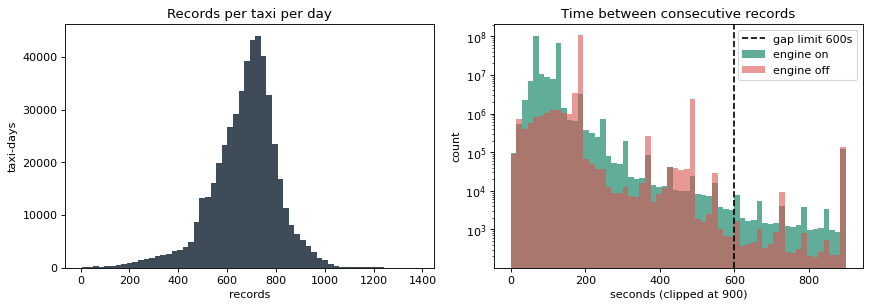

In [7]:
rpt = np.concatenate([s["records_per_taxi"] for s in S])
g_on, g_off = sum(s["gap_hist_on"] for s in S), sum(s["gap_hist_off"] for s in S)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(rpt, bins=60, color="#3E4C59")
ax[0].set(title="Records per taxi per day", xlabel="records", ylabel="taxi-days")
mid = (GAP_BINS[:-1] + GAP_BINS[1:]) / 2
ax[1].bar(mid, g_on, width=15, color="#1F8A70", alpha=0.7, label="engine on")
ax[1].bar(mid, g_off, width=15, color="#D9534F", alpha=0.6, label="engine off")
ax[1].axvline(GAP_SEC, color="k", ls="--", label=f"gap limit {GAP_SEC}s")
ax[1].set(title="Time between consecutive records", xlabel="seconds (clipped at 900)", ylabel="count", yscale="log")
ax[1].legend()
show(fig, "01_records_and_gaps.png")

def hist_median(h, bins):
    c = np.cumsum(h); return float(bins[np.searchsorted(c, c[-1] / 2)])
summary["median_gap_s_engine_on"] = hist_median(g_on, GAP_BINS)
summary["median_gap_s_engine_off"] = hist_median(g_off, GAP_BINS)
summary["share_gaps_over_limit"] = sum(s["n_gaps_over"] for s in S) / sum(s["n_gaps"] for s in S)
summary["median_records_per_taxi_day"] = float(np.median(rpt))
print({k: summary[k] for k in ["median_gap_s_engine_on", "median_gap_s_engine_off", "share_gaps_over_limit", "median_records_per_taxi_day"]})

## Step 5. Speeds

**Look for:** where the speed implied by consecutive points drops off. If the red line cuts real driving, change `MAX_SPEED_KMH` and rerun Step 2.

Removed speed jumps: 12976 | share of records stationary: 0.579


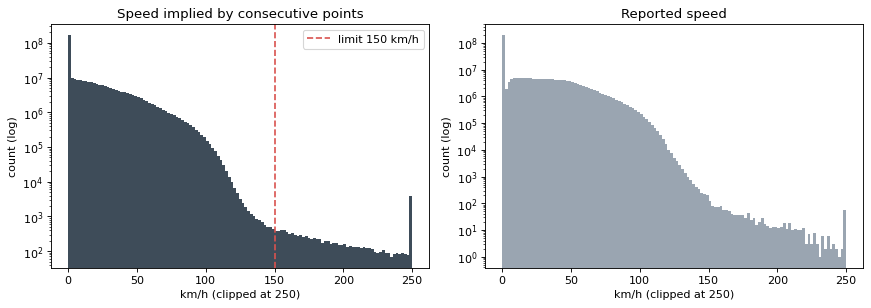

In [8]:
jh, sh = sum(s["jump_hist"] for s in S), sum(s["speed_hist"] for s in S)
mid = (SPD_BINS[:-1] + SPD_BINS[1:]) / 2
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(mid, jh, width=2, color="#3E4C59")
ax[0].axvline(MAX_SPEED_KMH, color="#D9534F", ls="--", label=f"limit {MAX_SPEED_KMH} km/h")
ax[0].set(title="Speed implied by consecutive points", xlabel="km/h (clipped at 250)", ylabel="count (log)", yscale="log")
ax[0].legend()
ax[1].bar(mid, sh, width=2, color="#9AA5B1")
ax[1].set(title="Reported speed", xlabel="km/h (clipped at 250)", ylabel="count (log)", yscale="log")
show(fig, "02_speed_distribution.png")
print("Removed speed jumps:", summary["removed_speed_jumps"], "| share of records stationary:", round(summary["share_stationary_records"], 3))

## Step 6. When are taxis occupied?

**Look for:** peak and quiet hours. Quiet hours are where drivers search the longest.

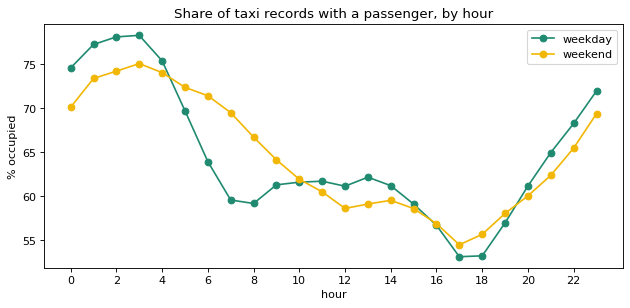

In [9]:
wk = np.array([pd.Timestamp(s["log"]["day"]).dayofweek >= 5 for s in S])
occ = {}
for name, mask in [("weekday", ~wk), ("weekend", wk)]:
    num = sum(s["occ_sum_by_hour"] for s, m in zip(S, mask) if m)
    den = sum(s["rows_by_hour"] for s, m in zip(S, mask) if m)
    occ[name] = 100 * num / den
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(24), occ["weekday"], marker="o", color="#1F8A70", label="weekday")
ax.plot(range(24), occ["weekend"], marker="o", color="#F2B705", label="weekend")
ax.set(title="Share of taxi records with a passenger, by hour", xlabel="hour", ylabel="% occupied", xticks=range(0, 24, 2))
ax.legend()
show(fig, "03_occupancy_by_hour.png")
summary["occupied_min_pct"], summary["occupied_max_pct"] = float(min(occ["weekday"])), float(max(occ["weekday"]))
summary["occupied_min_hour"], summary["occupied_max_hour"] = int(np.argmin(occ["weekday"])), int(np.argmax(occ["weekday"]))

## Step 7. How long do taxis wait, and how many periods are censored?

**Look for:** a long tail of waiting times, hours with many censored periods (a reason to use survival models), and whether long waits are mostly with the engine off (resting rather than searching).

{'median_taxis_per_day': 1385.0, 'share_stationary_records': 0.579, 'median_gap_s_engine_on': 60.0, 'median_gap_s_engine_off': 180.0, 'share_gaps_over_limit': 0.001, 'median_records_per_taxi_day': 689.0, 'trips': 5275990, 'vacant_periods': 5651362, 'share_censored': 0.02, 'share_breaks_over_3h': 0.019, 'median_wait_min_completed': 18.0, 'wait_p25': 10.0, 'wait_p75': 32.417, 'wait_p90': 53.75, 'median_trip_min': 20.55, 'median_trip_km': 4.708, 'share_vacant_mostly_engine_off': 0.026, 'wait_min_hour': 2, 'wait_min_value': 14.467, 'wait_max_hour': 17, 'wait_max_value': 21.717, 'censored_max_hour': 23, 'censored_max_pct': 1.913}


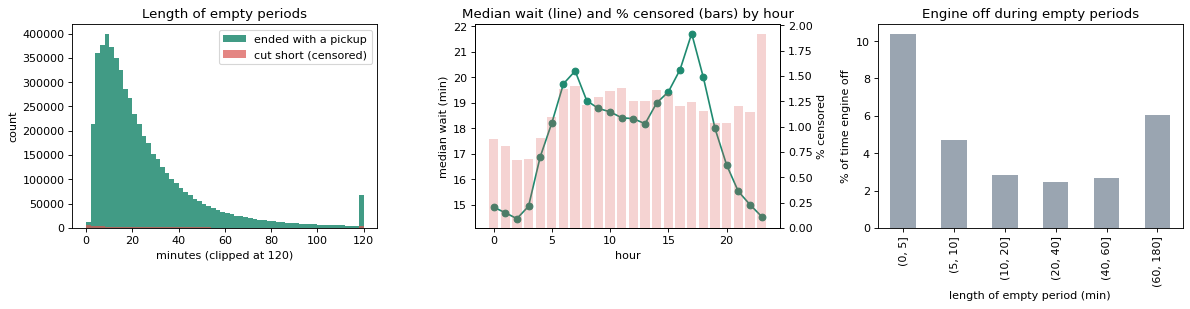

In [10]:
summary["trips"] = len(trips)
summary["vacant_periods"] = len(vac_all)
summary["share_censored"] = float(vac_all["censored"].mean())
summary["share_breaks_over_3h"] = float((vac_all["min"] > MAX_VACANT_MIN).mean())
vac = vac_all[vac_all["min"] <= MAX_VACANT_MIN].copy()
del vac_all
done, cens = vac.loc[~vac["censored"], "min"], vac.loc[vac["censored"], "min"]
summary["median_wait_min_completed"] = float(done.median())
summary["wait_p25"], summary["wait_p75"], summary["wait_p90"] = (float(done.quantile(q)) for q in (0.25, 0.75, 0.9))
summary["median_trip_min"], summary["median_trip_km"] = float(trips["min"].median()), float(trips["km"].median())
summary["share_vacant_mostly_engine_off"] = float((vac["engine_off_share"] > 0.5).mean())

bins = np.linspace(0, 120, 61)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(done.clip(upper=120), bins=bins, color="#1F8A70", alpha=0.85, label="ended with a pickup")
ax[0].hist(cens.clip(upper=120), bins=bins, color="#D9534F", alpha=0.7, label="cut short (censored)")
ax[0].set(title="Length of empty periods", xlabel="minutes (clipped at 120)", ylabel="count")
ax[0].legend()
med = vac[~vac["censored"]].groupby("hour")["min"].median()
cshare = vac.groupby("hour")["censored"].mean() * 100
ax[1].plot(med.index, med.values, marker="o", color="#1F8A70")
ax[1].set(title="Median wait (line) and % censored (bars) by hour", xlabel="hour", ylabel="median wait (min)")
ax2 = ax[1].twinx()
ax2.bar(cshare.index, cshare.values, color="#D9534F", alpha=0.25)
ax2.set_ylabel("% censored")
grp = pd.cut(vac["min"], [0, 5, 10, 20, 40, 60, 180])
vac.groupby(grp, observed=True)["engine_off_share"].mean().mul(100).plot(kind="bar", ax=ax[2], color="#9AA5B1")
ax[2].set(title="Engine off during empty periods", xlabel="length of empty period (min)", ylabel="% of time engine off")
show(fig, "04_vacant_periods.png")
summary["wait_min_hour"], summary["wait_min_value"] = int(med.idxmin()), float(med.min())
summary["wait_max_hour"], summary["wait_max_value"] = int(med.idxmax()), float(med.max())
summary["censored_max_hour"], summary["censored_max_pct"] = int(cshare.idxmax()), float(cshare.max())
print({k: round(v, 3) if isinstance(v, float) else v for k, v in summary.items() if k.startswith(("trips", "vacant", "share", "median", "wait", "censored"))})

## Step 8. Hexagon-hour table and weekly pattern

The hexagon-hour table (built in Step 2) has, for each hexagon and hour, the pickups, the empty taxis present and the median wait. This is the table Model A will learn from.

Active hexagons: 6987 | hexagon-hours with taxis but no pickup: 0.751


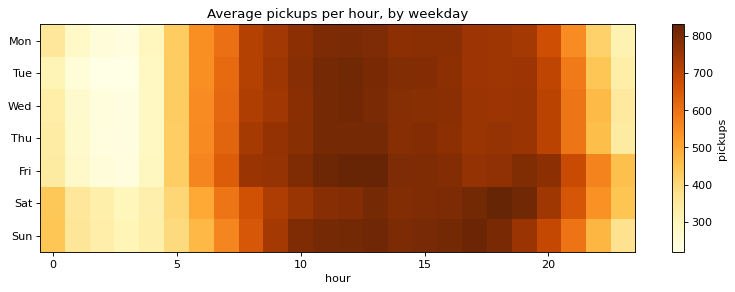

In [11]:
summary["active_hexagons"] = int(hh["hex"].nunique())
summary["share_hex_hours_zero_pickups"] = float((hh["pickups"] == 0).mean())

ndays = trips.groupby("dow")["day"].nunique()
grid = trips.groupby(["dow", "hour"]).size().unstack(fill_value=0).div(ndays, axis=0)
fig, ax = plt.subplots(figsize=(10, 3.8))
im = ax.imshow(grid.values, aspect="auto", cmap="YlOrBr")
ax.set(title="Average pickups per hour, by weekday", xlabel="hour", yticks=range(len(grid)),
       yticklabels=[["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"][i] for i in grid.index])
fig.colorbar(im, ax=ax, label="pickups")
show(fig, "05_pickups_weekday_hour.png")
print("Active hexagons:", summary["active_hexagons"], "| hexagon-hours with taxis but no pickup:", round(summary["share_hex_hours_zero_pickups"], 3))

## Step 9. Map of pickups by hexagon

This is exactly what the **heat-map baseline** uses: where pickups usually happen.

Hexagons that hold half of all pickups: 344


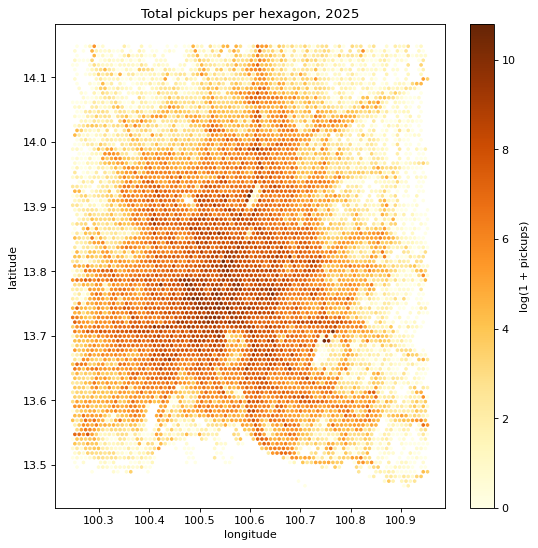

In [12]:
by_hex = hh.groupby("hex").agg(pickups=("pickups", "sum"), vacant=("vacant_taxis", "mean")).reset_index()
cent = hex_center(by_hex["hex"].to_numpy())
by_hex["lat"], by_hex["lon"] = cent[:, 0], cent[:, 1]
fig, ax = plt.subplots(figsize=(7, 7))
sc = ax.scatter(by_hex["lon"], by_hex["lat"], c=np.log1p(by_hex["pickups"]), s=6, cmap="YlOrBr", marker="h")
ax.set(title="Total pickups per hexagon, 2025", xlabel="longitude", ylabel="latitude")
fig.colorbar(sc, ax=ax, label="log(1 + pickups)")
show(fig, "06_pickups_map.png")
s = by_hex["pickups"].sort_values(ascending=False)
summary["hexagons_for_half_of_pickups"] = int((s.cumsum() / s.sum() < 0.5).sum() + 1)
print("Hexagons that hold half of all pickups:", summary["hexagons_for_half_of_pickups"])

## Step 10. Key check: are busy hexagons also fast?

The Bangkok study found demand alone does not predict search time. If busy hexagons do **not** have shorter waits (correlation near zero or positive), a heat map is not enough. The second plot checks competition: do more empty taxis per pickup mean a longer wait?

Spearman pickups vs wait: -0.22 | competition vs wait: 0.03 | median wait lowest/highest competition: 19.0 20.4


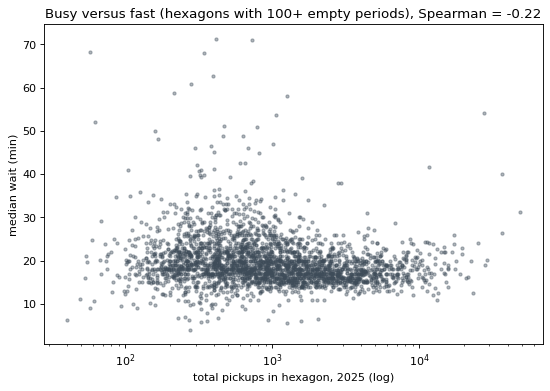

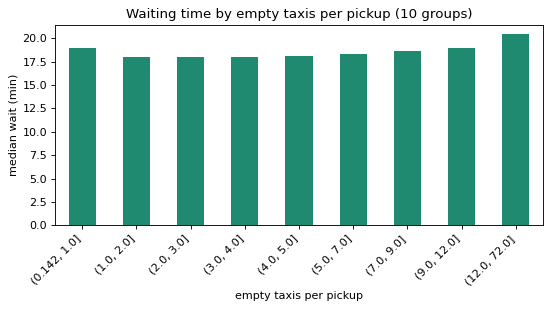

In [13]:
w_hex = vac[~vac["censored"]].groupby("hex")["min"].agg(["median", "size"]).rename(columns={"median": "wait", "size": "n"})
cmp = by_hex.set_index("hex").join(w_hex, how="inner")
cmp = cmp[cmp["n"] >= 100]
corr = cmp[["pickups", "wait"]].corr(method="spearman").iloc[0, 1]
summary["hexagons_with_100plus_periods"] = len(cmp)
summary["spearman_pickups_vs_wait"] = float(corr)
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(cmp["pickups"], cmp["wait"], s=8, alpha=0.4, color="#3E4C59")
ax.set(xscale="log", title=f"Busy versus fast (hexagons with 100+ empty periods), Spearman = {corr:.2f}",
       xlabel="total pickups in hexagon, 2025 (log)", ylabel="median wait (min)")
show(fig, "07_wait_vs_pickups.png")

comp = hh.dropna(subset=["median_wait", "vacant_taxis"])
comp = comp.assign(ratio=comp["vacant_taxis"] / comp["pickups"].clip(lower=1))
summary["spearman_competition_vs_wait"] = float(comp[["ratio", "median_wait"]].corr(method="spearman").iloc[0, 1])
q = pd.qcut(comp["ratio"], 10, duplicates="drop")
dec = comp.groupby(q, observed=True)["median_wait"].median()
summary["wait_lowest_competition"], summary["wait_highest_competition"] = float(dec.iloc[0]), float(dec.iloc[-1])
fig, ax = plt.subplots(figsize=(7, 4))
dec.plot(kind="bar", ax=ax, color="#1F8A70")
ax.set(title="Waiting time by empty taxis per pickup (10 groups)", xlabel="empty taxis per pickup", ylabel="median wait (min)")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
show(fig, "08_competition_vs_wait.png")
print("Spearman pickups vs wait:", round(corr, 2), "| competition vs wait:", round(summary["spearman_competition_vs_wait"], 2),
      "| median wait lowest/highest competition:", round(dec.iloc[0], 1), round(dec.iloc[-1], 1))

## Step 11. Weather, holidays and the year

**Look for:** more pickups and different waits in rainy hours, the effect of holidays such as Songkran, and changes across the year.

Weather download skipped: HTTPSConnectionPool(host='archive-api.open-meteo.com', port=443): Max retries exceeded with url: /v1/archive?latitude=13.75&longitude=100.5&start_date=2025-01-01&end_date=2025-12-31&hourly=temperature_2m%2Cprecipitation&timezone=Asia%2FBangkok (Caused by ProxyError('Unable to connect to proxy', OSError('Tunnel connection failed: 403 Forbidden')))


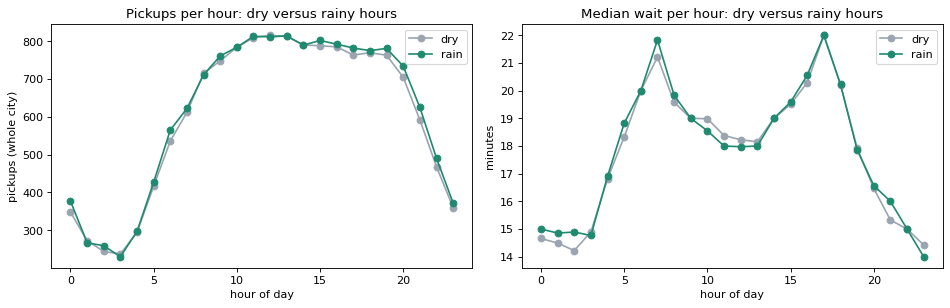

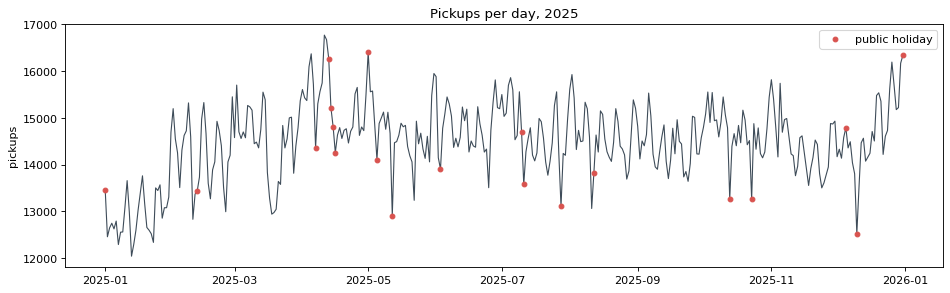

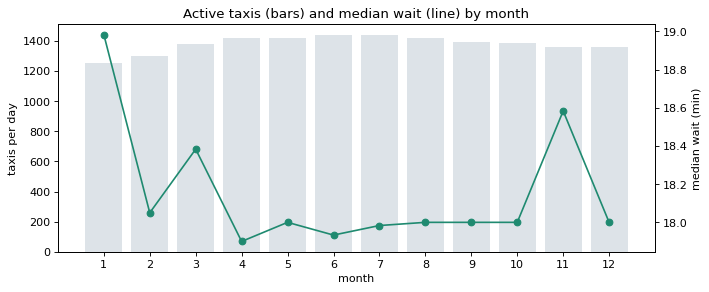

In [14]:
city_hour = trips.groupby("hour_id").size().rename("pickups").to_frame()
city_hour["wait"] = vac.loc[~vac["censored"], ["hour_id", "min"]].astype({"min": "float64"}).groupby("hour_id")["min"].median()
weather_ok = False
if DOWNLOAD_WEATHER:
    try:
        import requests
        r = requests.get("https://archive-api.open-meteo.com/v1/archive", timeout=120, params={
            "latitude": 13.75, "longitude": 100.50, "start_date": str(pd.to_datetime(trips["day"].min(), unit="D").date()), "end_date": str(pd.to_datetime(trips["day"].max(), unit="D").date()),
            "hourly": "temperature_2m,precipitation", "timezone": "Asia/Bangkok"})
        r.raise_for_status()
        w = pd.DataFrame(r.json()["hourly"])
        w.to_csv(os.path.join(OUT, "weather_hourly.csv"), index=False)
        weather_ok = True
    except Exception as e:
        print("Weather download skipped:", e)
if not weather_ok and os.path.exists(os.path.join(OUT, "weather_hourly.csv")):
    w = pd.read_csv(os.path.join(OUT, "weather_hourly.csv")); weather_ok = True
if weather_ok:
    w["hour_id"] = (pd.to_datetime(w["time"]).astype("int64") // 10**9 // 3600)
    city_hour = city_hour.join(w.set_index("hour_id")[["temperature_2m", "precipitation"]], how="left")
    city_hour["rain"] = city_hour["precipitation"] > 0.1
    city_hour["hod"] = (city_hour.index % 24)
    summary["rainy_hours"] = int(city_hour["rain"].sum())
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for col, a, ttl, yl in [("pickups", ax[0], "Pickups per hour", "pickups (whole city)"), ("wait", ax[1], "Median wait per hour", "minutes")]:
        e = city_hour.groupby(["hod", "rain"])[col].median().unstack()
        e.plot(ax=a, marker="o", color=["#9AA5B1", "#1F8A70"][:e.shape[1]])
        a.set(title=ttl + ": dry versus rainy hours", xlabel="hour of day", ylabel=yl)
        a.legend(["dry", "rain"])
    show(fig, "09_weather.png")
    summary["pickups_ratio_rain_vs_dry"] = float(city_hour.loc[city_hour["rain"], "pickups"].median() / city_hour.loc[~city_hour["rain"], "pickups"].median())
    summary["wait_rain_minus_dry_min"] = float(city_hour.loc[city_hour["rain"], "wait"].median() - city_hour.loc[~city_hour["rain"], "wait"].median())

try:
    import holidays
    th = set(holidays.TH(years=2025).keys())
except ImportError:      # official 2025 Thai public holidays (main dates)
    th = {pd.Timestamp(x).date() for x in ["2025-01-01", "2025-02-12", "2025-04-07", "2025-04-13", "2025-04-14", "2025-04-15",
          "2025-04-16", "2025-05-01", "2025-05-05", "2025-05-12", "2025-06-03", "2025-07-10", "2025-07-11", "2025-07-28",
          "2025-08-12", "2025-10-13", "2025-10-23", "2025-12-05", "2025-12-10", "2025-12-31"]}
daily = trips.groupby("day").size()
daily.index = pd.to_datetime(daily.index, unit="D")
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(daily.index, daily.values, color="#3E4C59", lw=1)
hol = daily[[d.date() in th for d in daily.index]]
ax.scatter(hol.index, hol.values, color="#D9534F", s=18, zorder=3, label="public holiday")
ax.set(title="Pickups per day, 2025", ylabel="pickups")
ax.legend()
show(fig, "10_daily_pickups.png")
summary["median_daily_pickups"] = float(daily.median())
summary["median_daily_pickups_holiday"] = float(hol.median()) if len(hol) else float("nan")

monthly = pd.DataFrame({"taxis_per_day": log.assign(m=log["day"].str[4:6].astype(int)).groupby("m")["taxis"].median(),
                        "median_wait": vac[~vac["censored"]].groupby("month")["min"].median()})
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(monthly.index, monthly["taxis_per_day"], color="#DDE3E8", label="taxis per day")
ax.set(xlabel="month", ylabel="taxis per day", xticks=range(1, 13))
ax2 = ax.twinx()
ax2.plot(monthly.index, monthly["median_wait"], marker="o", color="#1F8A70", label="median wait")
ax2.set_ylabel("median wait (min)")
ax.set_title("Active taxis (bars) and median wait (line) by month")
show(fig, "12_monthly.png")

## Step 12. Trips and estimated fares

GPS data has no fares, so fares are estimated from the Bangkok fare schedule (35 baht first km, then a rate per km that rises with distance, plus 3 baht per minute at 6 km/h or less). These estimates are used only for the earnings variant of the score.

Median trip: 4.7 km, 21 min | median estimated fare: 96 baht


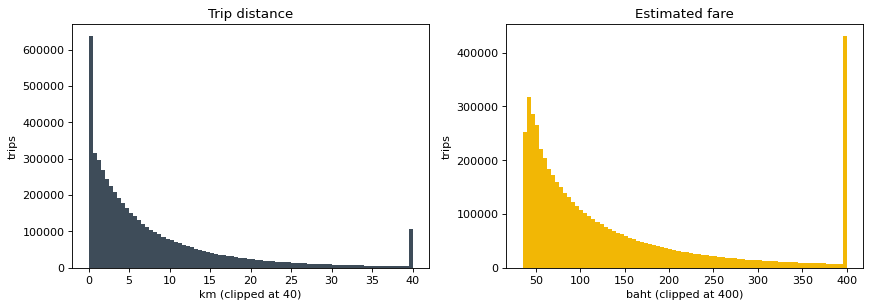

In [15]:
summary["median_fare_est_baht"] = float(trips["fare_est"].median())
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(trips["km"].clip(upper=40), bins=80, color="#3E4C59")
ax[0].set(title="Trip distance", xlabel="km (clipped at 40)", ylabel="trips")
ax[1].hist(trips["fare_est"].clip(upper=400), bins=80, color="#F2B705")
ax[1].set(title="Estimated fare", xlabel="baht (clipped at 400)", ylabel="trips")
show(fig, "11_trips_and_fares.png")
print("Median trip:", round(summary["median_trip_km"], 1), "km,", round(summary["median_trip_min"]), "min | median estimated fare:", round(summary["median_fare_est_baht"]), "baht")

## Step 13. Save the tables and the summary

In [16]:
for name, table in [("trips", trips), ("vacant_periods", vac), ("hexagon_hour", hh), ("daily_load_log", log)]:
    try:
        table.to_parquet(os.path.join(OUT, name + ".parquet"), index=False)
    except ImportError:
        table.to_pickle(os.path.join(OUT, name + ".pkl"))
pd.Series(summary).to_csv(os.path.join(OUT, "eda_summary.csv"), header=["value"])
pd.Series(summary).to_frame("value")

,value
hexagon_grid,hexgrid
days,365
low_coverage_days,20250829
first_day,20250101
last_day,20251231
raw_rows_all_vehicles,872452985
removed_invalid_or_wrong_day,3653249
removed_outside_bangkok,200008923
taxi_rows,336083922
median_taxis_per_day,1385.0


## What to report from this notebook

1. Data size and filtering: days, all-vehicle rows, taxis per day, rows removed by each filter (Steps 1 to 5).
2. Reporting intervals with the engine on and off, and the gap limit chosen (Step 4).
3. Daily, weekly and monthly patterns (Steps 6, 8 and 11).
4. Median wait, share censored, and the engine-off check (Step 7).
5. Busy versus fast and competition (Step 10): the early evidence for predicting waiting time.
6. Rain and holidays (Step 11), and estimated fares (Step 12).